# Assessment 2: Machine Learning and Real Time Streaming
Student ID: 33602190  
Unit: ITO5202  
Year: 2026

This assessment uses the IBM AML HI-Small dataset from Assessment 1. Part A compares classification models and saves the selected model. Part B uses that model to predict transactions sent through Kafka.

## 0. Environment and configuration
Start Kafka with `bash scripts/start_kafka.sh` in a separate terminal. Open the notebook with `bash scripts/start_notebook.sh`, select Python (assessment2-aml) and run the cells in order.

File paths start from the project folder. The split uses seed 42, and Spark uses UTC for timestamps. Spark downloads the Kafka connector on its first run.

In [1]:
from pathlib import Path
import os
import sys
import platform
from importlib.metadata import version

PROJECT_ROOT = Path.cwd().resolve()
assert (PROJECT_ROOT / "requirements.txt").exists(), "Use the repo root."
JAVA_HOME = PROJECT_ROOT / ".runtime/jdk-17.0.20.1+1/Contents/Home"
assert (JAVA_HOME / "bin/java").exists(), "Install Java; see README."
expected_environment = (PROJECT_ROOT / ".venv").resolve()
assert Path(sys.prefix).resolve() == expected_environment, "Use the A2 kernel."
os.environ["JAVA_HOME"] = str(JAVA_HOME)
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_SUBMIT_ARGS"] = "--driver-memory 4g pyspark-shell"

SEED = 42
DATA_DIR = PROJECT_ROOT / "data"
MODEL_PATH = PROJECT_ROOT / "models/a2_model"
STREAM_PATH = DATA_DIR / "stream_data.parquet"
DEVELOPMENT_PATH = DATA_DIR / "development_data.parquet"
KAFKA_BOOTSTRAP_SERVERS = "127.0.0.1:9092"
KAFKA_TOPIC = "aml-transactions"
RUN_KAFKA_SMOKE_TEST = True
SPARK_KAFKA_PACKAGE = "org.apache.spark:spark-sql-kafka-0-10_2.12:3.5.7"

assert platform.python_version() == "3.11.17"
assert version("pyspark") == "3.5.7"
print("Python:", platform.python_version())
print("PySpark:", version("pyspark"))
print("Kafka Python client:", version("kafka-python3"))
print("Kernel: assessment2-aml")

Python: 3.11.17
PySpark: 3.5.7
Kafka Python client: 3.0.0
Kernel: assessment2-aml


### Start Spark
Spark runs with four local threads and 4 GB of driver memory. The Kafka connector matches Spark 3.5.7 and Scala 2.12. The Kafka server uses its own Scala 2.13 build.

In [2]:
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder
         .master("local[4]")
         .appName("Assessment2-AML")
         .config("spark.jars.packages", SPARK_KAFKA_PACKAGE)
         .config("spark.jars.ivy", str(PROJECT_ROOT / ".runtime/ivy"))
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
jvm = spark.sparkContext._jvm
java_version = jvm.java.lang.System.getProperty("java.version")
scala_version = jvm.scala.util.Properties.versionNumberString()
assert java_version.startswith("17.")
assert scala_version.startswith("2.12.")
assert spark.range(10).agg(F.sum("id")).first()[0] == 45
print(f"PASS: Spark {spark.version}, Java {java_version}, Scala {scala_version}")
print("PASS: local Spark computation (sum 0–9 = 45)")

:: loading settings :: url = jar:file:/Users/a208109/Desktop/assessment2-aml/.venv/lib/python3.11/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


PASS: Spark 3.5.7, Java 17.0.20.1, Scala 2.12.18
PASS: local Spark computation (sum 0–9 = 45)


### Check Kafka and Structured Streaming
This check sends a sample JSON array through Kafka and reads it with Python and Spark. It removes the temporary topic when finished. Kafka needs to be running at `127.0.0.1:9092`.

Set `RUN_KAFKA_SMOKE_TEST = False` to skip this check when working offline.

In [3]:
from scripts.check_kafka import check_kafka

if RUN_KAFKA_SMOKE_TEST:
    setup_result = check_kafka(spark, PROJECT_ROOT, KAFKA_BOOTSTRAP_SERVERS)
    print(setup_result)
else:
    print("SKIPPED: Kafka connectivity check")

PASS: Python producer and consumer exchanged one JSON array.


PASS: Spark Structured Streaming parsed the same record using the Kafka connector.
{'python_round_trip': 'PASS', 'spark_streaming': 'PASS', 'records': 1}


## Part A: Machine learning
### A1. Load and validate the dataset

The task is binary classification using `is_laundering` as the target. A value of 1 means simulated laundering, and 0 means no laundering. The aim is to identify transactions that may need review.

The data comes from the HI-Small subset of [IBM Transactions for Anti-Money Laundering (AML)](https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml), which was approved for Assessment 1. Each row in the transaction file represents a transaction. The account file provides bank and account details.

#### Check the input files
The checksums are compared with those recorded in Assessment 1. The CSV headers are also checked before the columns are renamed.

In [4]:
import csv
import hashlib
from html import escape
from IPython.display import HTML, display


def show_table(headers, rows):
    header = "".join(f"<th>{escape(str(x))}</th>" for x in headers)
    body = "".join(
        "<tr>" + "".join(f"<td>{escape(str(x))}</td>" for x in row) + "</tr>"
        for row in rows
    )
    display(HTML(f"<table><thead><tr>{header}</tr></thead>"
                 f"<tbody>{body}</tbody></table>"))


expected_hashes = {
    "HI-Small_Trans.csv":
        "b19d39f515523373f991b689c07e11e7b0b95c17a2c27a87d91584ae16c5b040",
    "HI-Small_accounts.csv":
        "786808526e33cfc441212dd6fccda7edfc24172149bed59c6ef59b186836b014",
}
expected_headers = {
    "HI-Small_Trans.csv": [
        "Timestamp", "From Bank", "Account", "To Bank", "Account",
        "Amount Received", "Receiving Currency", "Amount Paid",
        "Payment Currency", "Payment Format", "Is Laundering",
    ],
    "HI-Small_accounts.csv": [
        "Bank Name", "Bank ID", "Account Number", "Entity ID", "Entity Name",
    ],
}
file_checks = []
for filename, expected_hash in expected_hashes.items():
    path = DATA_DIR / filename
    assert path.is_file(), f"Missing {filename}; see data/README.md."
    with path.open("rb") as file:
        actual_hash = hashlib.file_digest(file, "sha256").hexdigest()
    assert actual_hash == expected_hash, f"Checksum mismatch: {filename}"
    with path.open(newline="", encoding="utf-8-sig") as file:
        header = next(csv.reader(file))
    assert header == expected_headers[filename], f"Header mismatch: {filename}"
    file_checks.append((filename, "Matches Assessment 1", "Matches"))
show_table(["File", "SHA-256", "Header"], file_checks)

File,SHA-256,Header
HI-Small_Trans.csv,Matches Assessment 1,Matches
HI-Small_accounts.csv,Matches Assessment 1,Matches


#### Load the data
Account numbers are kept as strings. The two columns named `Account` are renamed `sender_account` and `receiver_account`. Bank IDs are numeric in both files. Loading stops if a record cannot be parsed. No rows are removed.

The timestamp format is `yyyy/MM/dd HH:mm`. The source does not specify a timezone, so UTC is used consistently without changing the recorded clock times. Amounts use double precision and are interpreted in their own currencies.

In [5]:
from pyspark import StorageLevel
from pyspark.sql.types import (
    StructType, StructField, TimestampType, LongType,
    StringType, DoubleType, IntegerType,
)

transaction_schema = StructType([
    StructField("timestamp", TimestampType(), True),
    StructField("from_bank", LongType(), True),
    StructField("sender_account", StringType(), True),
    StructField("to_bank", LongType(), True),
    StructField("receiver_account", StringType(), True),
    StructField("amount_received", DoubleType(), True),
    StructField("receiving_currency", StringType(), True),
    StructField("amount_paid", DoubleType(), True),
    StructField("payment_currency", StringType(), True),
    StructField("payment_format", StringType(), True),
    StructField("is_laundering", IntegerType(), True),
])
account_schema = StructType([
    StructField("bank_name", StringType(), True),
    StructField("bank_id", LongType(), True),
    StructField("account_number", StringType(), True),
    StructField("entity_id", StringType(), True),
    StructField("entity_name", StringType(), True),
])

transactions = (
    spark.read.schema(transaction_schema)
    .option("header", True).option("enforceSchema", True)
    .option("timestampFormat", "yyyy/MM/dd HH:mm")
    .option("mode", "FAILFAST")
    .csv(str(DATA_DIR / "HI-Small_Trans.csv"))
    .persist(StorageLevel.MEMORY_AND_DISK)
)
accounts = (
    spark.read.schema(account_schema)
    .option("header", True).option("enforceSchema", True)
    .option("mode", "FAILFAST")
    .csv(str(DATA_DIR / "HI-Small_accounts.csv"))
    .persist(StorageLevel.MEMORY_AND_DISK)
)
transaction_count = transactions.count()
account_count = accounts.count()
assert transaction_count == 5_078_345
assert account_count == 518_581
show_table(["Dataset", "Rows", "Columns"], [
    ("Transactions", f"{transaction_count:,}", len(transactions.columns)),
    ("Accounts", f"{account_count:,}", len(accounts.columns)),
])
show_table(["Dataset", "Field", "Spark type"], [
    (name, field.name, field.dataType.simpleString())
    for name, dataframe in [("Transactions", transactions), ("Accounts", accounts)]
    for field in dataframe.schema.fields
])

Dataset,Rows,Columns
Transactions,"5,078,345",11
Accounts,"518,581",5


Dataset,Field,Spark type
Transactions,timestamp,timestamp
Transactions,from_bank,bigint
Transactions,sender_account,string
Transactions,to_bank,bigint
Transactions,receiver_account,string
Transactions,amount_received,double
Transactions,receiving_currency,string
Transactions,amount_paid,double
Transactions,payment_currency,string
Transactions,payment_format,string


#### Check missing and invalid values
Check each column for nulls and text columns for blanks. Amounts must be finite and at least zero. Labels must be 0 or 1. The timestamp check also identifies missing dates after parsing.

In [6]:
missing_results = []
for name, dataframe in [("Transactions", transactions), ("Accounts", accounts)]:
    expressions = []
    for field in dataframe.schema.fields:
        missing = F.col(field.name).isNull()
        if isinstance(field.dataType, StringType):
            missing = missing | (F.trim(F.col(field.name)) == "")
        expressions.append(
            F.sum(F.when(missing, 1).otherwise(0)).alias(field.name)
        )
    counts = dataframe.agg(*expressions).first().asDict()
    missing_results.extend((name, column, count) for column, count in counts.items())
show_table(["Dataset", "Field", "Null or blank rows"], missing_results)
assert all(count == 0 for _, _, count in missing_results)

invalid_checks = {
    "invalid_labels": (
        F.col("is_laundering").isNull() | ~F.col("is_laundering").isin(0, 1)
    ),
}
for column in ["amount_paid", "amount_received"]:
    invalid_checks[f"invalid_{column}"] = (
        F.col(column).isNull() | F.isnan(column)
        | (F.abs(F.col(column)) == float("inf")) | (F.col(column) < 0)
    )
invalid_results = transactions.agg(*[
    F.sum(F.when(condition, 1).otherwise(0)).alias(name)
    for name, condition in invalid_checks.items()
]).first().asDict()
show_table(["Check", "Invalid rows"], invalid_results.items())
assert all(count == 0 for count in invalid_results.values())

Dataset,Field,Null or blank rows
Transactions,timestamp,0
Transactions,from_bank,0
Transactions,sender_account,0
Transactions,to_bank,0
Transactions,receiver_account,0
Transactions,amount_received,0
Transactions,receiving_currency,0
Transactions,amount_paid,0
Transactions,payment_currency,0
Transactions,payment_format,0


Check,Invalid rows
invalid_labels,0
invalid_amount_paid,0
invalid_amount_received,0


#### Check dates and labels
Compare the date range and label counts with Assessment 1. These checks cover the original files. Model development uses the separate development data created in A2.

In [7]:
# Keep the displayed dates in UTC.
coverage_display = transactions.agg(
    F.date_format(F.min("timestamp"), "yyyy-MM-dd HH:mm").alias("first"),
    F.date_format(F.max("timestamp"), "yyyy-MM-dd HH:mm").alias("last"),
).first()
show_table(["First transaction", "Last transaction", "Processing timezone"], [
    (coverage_display["first"], coverage_display["last"],
     spark.conf.get("spark.sql.session.timeZone")),
])
label_counts = transactions.groupBy("is_laundering").count().orderBy(
    "is_laundering"
).collect()
show_table(["Label", "Transactions", "Percent"], [
    (row.is_laundering, f"{row['count']:,}",
     f"{100 * row['count'] / transaction_count:.4f}%")
    for row in label_counts
])
assert {row.is_laundering: row["count"] for row in label_counts} == {
    0: 5_073_168, 1: 5_177,
}

First transaction,Last transaction,Processing timezone
2022-09-01 00:00,2022-09-18 16:18,UTC


Label,Transactions,Percent
0,"5,073,168",99.8981%
1,"5,177",0.1019%


#### Check account matches
An account is identified by its bank ID and account number together. Check that this combination is unique, then count transactions whose sender or receiver has no matching account. This helps prevent joins from duplicating or dropping transactions.

In [8]:
duplicate_account_keys = (
    accounts.groupBy("bank_id", "account_number").count()
    .filter(F.col("count") > 1).count()
)
account_keys = accounts.select("bank_id", "account_number")
unmatched_senders = transactions.join(
    account_keys,
    (transactions.from_bank == account_keys.bank_id)
    & (transactions.sender_account == account_keys.account_number),
    "left_anti",
).count()
unmatched_receivers = transactions.join(
    account_keys,
    (transactions.to_bank == account_keys.bank_id)
    & (transactions.receiver_account == account_keys.account_number),
    "left_anti",
).count()
join_checks = [
    ("Duplicate account key groups", duplicate_account_keys),
    ("Transactions without sender account", unmatched_senders),
    ("Transactions without receiver account", unmatched_receivers),
]
show_table(["Check", "Count"], join_checks)
assert all(count == 0 for _, count in join_checks)

Check,Count
Duplicate account key groups,0
Transactions without sender account,0
Transactions without receiver account,0


#### Check duplicate transactions
The source has no transaction ID. Compare the ten fields other than the label to find repeated transactions and any conflicting labels. Exact duplicates have the same values in all eleven fields. Keep all rows during these checks.

In [9]:
transaction_content_columns = [
    column for column in transactions.columns if column != "is_laundering"
]
content_groups = transactions.groupBy(*transaction_content_columns).agg(
    F.count("*").alias("source_rows"),
    F.countDistinct("is_laundering").alias("label_variants"),
)
duplicate_summary = content_groups.agg(
    F.sum(F.when(F.col("source_rows") > 1, 1).otherwise(0))
     .alias("repeated_content_groups"),
    F.sum(F.when(F.col("source_rows") > 1, F.col("source_rows")).otherwise(0))
     .alias("rows_in_repeated_groups"),
    F.sum(F.col("source_rows") - F.col("label_variants"))
     .alias("exact_duplicate_excess_rows"),
    F.sum(F.when(F.col("label_variants") > 1, 1).otherwise(0))
     .alias("conflicting_label_groups"),
).first().asDict()
show_table(["Check", "Count"], [
    (name.replace("_", " ").capitalize(), f"{count:,}")
    for name, count in duplicate_summary.items()
])
print("Source rows retained:", f"{transaction_count:,}")

Check,Count
Repeated content groups,9
Rows in repeated groups,18
Exact duplicate excess rows,9
Conflicting label groups,0


Source rows retained: 5,078,345


#### Validation results
The files contain 5,078,345 transactions and 518,581 accounts, matching Assessment 1. There are no missing values or invalid labels. Both amount fields contain finite values of zero or more. The dates run from 1 September 2022 at 00:00 to 18 September 2022 at 16:18, using UTC for processing.

Every sender and receiver matches an account. The combination of bank ID and account number is unique. There are 5,177 transactions labelled as laundering, or 0.1019% of all transactions. This imbalance needs to be considered when evaluating the models.

Nine pairs have identical transaction details and labels. This gives 18 rows in duplicate groups and nine extra duplicate rows. There are no conflicting labels. Without transaction IDs, it is not possible to tell whether these are duplicate entries or separate events with identical details, so all rows are kept. A2 keeps each pair in the same partition. Different transactions involving the same account can still appear in different partitions.

### A2. Split the development and streaming data

The split targets 75% for development and 25% for streaming. This meets the assignment minimums of 70% and 20%. The streaming data is reserved for Part B before fitting any preprocessing or model.

The nine duplicate pairs need to stay together. A SHA-256 key groups transactions using the ten fields other than the label. A hash calculation includes seed 42 as a salt to assign each group to a partition. The resulting percentages are checked because they will not be exactly 75% and 25%.

Within development, seed 43 is used to target 70% training, 15% validation and 15% testing. Duplicate pairs stay together here as well. Training data is used to fit preprocessing and models. Validation data is used to choose the model and prediction threshold. Test data is reserved for the final evaluation. The split mixes transaction dates and can include the same account in different partitions.

#### Add source row IDs
`source_record_id` is the transaction's position in the original CSV, starting at 1 after the header. Identical rows receive different IDs. Each record occupies one line in this file. The counts and contents are checked against A1 after adding the IDs. Keeping the original file order preserves these IDs.

In [10]:
raw_lines = spark.sparkContext.textFile(
    str(DATA_DIR / "HI-Small_Trans.csv"), minPartitions=4
)
indexed_lines = raw_lines.zipWithIndex().filter(lambda item: item[1] > 0)
numbered_lines = spark.createDataFrame(
    indexed_lines.map(lambda item: (item[1], item[0])),
    "source_record_id long, raw_csv string",
)
identified_transactions = (
    numbered_lines.select(
        "source_record_id",
        F.from_csv(
            "raw_csv", transaction_schema.simpleString(),
            {"mode": "FAILFAST", "timestampFormat": "yyyy/MM/dd HH:mm"},
        ).alias("record"),
    )
    .select("source_record_id", "record.*")
    .withColumn(
        "transaction_group_id",
        F.sha2(F.to_json(F.struct(*transaction_content_columns)), 256),
    )
    .persist(StorageLevel.DISK_ONLY)
)
id_summary = identified_transactions.agg(
    F.count("*").alias("rows"),
    F.countDistinct("source_record_id").alias("unique_ids"),
    F.min("source_record_id").alias("first_id"),
    F.max("source_record_id").alias("last_id"),
).first()
assert id_summary.rows == id_summary.unique_ids == transaction_count
assert id_summary.first_id == 1 and id_summary.last_id == transaction_count
assert transactions.exceptAll(
    identified_transactions.select(*transactions.columns)
).limit(1).count() == 0
show_table(["Check", "Result"], [
    ("Source rows and unique IDs", f"{id_summary.rows:,}"),
    ("First / last source ID", f"1 / {id_summary.last_id:,}"),
    ("Original transaction content", "Exact match, including duplicates"),
])
transactions.unpersist()
accounts.unpersist()

Check,Result
Source rows and unique IDs,"5,078,345"
First / last source ID,"1 / 5,078,345"
Original transaction content,"Exact match, including duplicates"


DataFrame[bank_name: string, bank_id: bigint, account_number: string, entity_id: string, entity_name: string]

#### Assign the partitions
The assignment uses the transaction group key and a fixed salt. It does not use the label or row position. Hash values are mapped to buckets from 0 to 999,999. With seed 42, the first 750,000 buckets go to development. Seed 43 divides development into training, validation and test data.

The row ID, group ID and partition columns are used to check the split. They are excluded from model features.

In [11]:
MODEL_SPLIT_SEED = 43
HASH_BUCKETS = 1_000_000


def hash_bucket(seed):
    return F.pmod(
        F.xxhash64("transaction_group_id", F.lit(seed)),
        F.lit(HASH_BUCKETS),
    )


def assign_partitions(dataframe):
    outer_bucket = hash_bucket(SEED)
    inner_bucket = hash_bucket(MODEL_SPLIT_SEED)
    return (
        dataframe.withColumn(
            "data_partition",
            F.when(outer_bucket < 750_000, "development").otherwise("stream"),
        )
        .withColumn(
            "model_partition",
            F.when(F.col("data_partition") == "stream", "stream")
             .when(inner_bucket < 700_000, "train")
             .when(inner_bucket < 850_000, "validation")
             .otherwise("test"),
        )
    )


partitioned_transactions = assign_partitions(
    identified_transactions
).persist(StorageLevel.DISK_ONLY)
outer_counts = {
    row.data_partition: row["count"]
    for row in partitioned_transactions.groupBy("data_partition").count().collect()
}
assert sum(outer_counts.values()) == transaction_count
assert outer_counts["development"] / transaction_count >= 0.70
assert outer_counts["stream"] / transaction_count >= 0.20
show_table(["Partition", "Rows", "Percent of source"], [
    (name, f"{outer_counts[name]:,}",
     f"{100 * outer_counts[name] / transaction_count:.4f}%")
    for name in ["development", "stream"]
])

Partition,Rows,Percent of source
development,"3,808,651",74.9979%
stream,"1,269,694",25.0021%


#### Check the split
Check that every source row appears once and that each transaction group belongs to only one partition. Repeat the assignment after changing the number of Spark partitions to confirm that the result stays the same.

In [12]:
partition_id_count = partitioned_transactions.select(
    "source_record_id"
).distinct().count()
assert partition_id_count == transaction_count
cross_partition_groups = (
    partitioned_transactions.groupBy("transaction_group_id")
    .agg(F.countDistinct("model_partition").alias("partitions"))
    .filter(F.col("partitions") != 1).count()
)
assert cross_partition_groups == 0
repeated_assignments = assign_partitions(
    identified_transactions.repartition(3)
).select("source_record_id", "data_partition", "model_partition")
assignment_changes = repeated_assignments.exceptAll(
    partitioned_transactions.select(
        "source_record_id", "data_partition", "model_partition"
    )
).limit(1).count()
assert assignment_changes == 0
show_table(["Check", "Result"], [
    ("Complete source-row coverage", f"{partition_id_count:,} unique IDs"),
    ("Content groups crossing partitions", cross_partition_groups),
    ("Assignment changes after repartitioning", assignment_changes),
])

Check,Result
Complete source-row coverage,"5,078,345 unique IDs"
Content groups crossing partitions,0
Assignment changes after repartitioning,0


#### Check the development groups
Count the labels in training, validation and test data to confirm that both classes are present. Streaming labels are not used to select features, tune models or evaluate Part A.

In [13]:
development_source = partitioned_transactions.filter(
    F.col("data_partition") == "development"
)
stream_source = partitioned_transactions.filter(F.col("data_partition") == "stream")
model_counts = {
    row.model_partition: row.asDict()
    for row in development_source.groupBy("model_partition").agg(
        F.count("*").alias("rows"),
        F.sum(F.when(F.col("is_laundering") == 0, 1).otherwise(0)).alias("negative"),
        F.sum(F.when(F.col("is_laundering") == 1, 1).otherwise(0)).alias("positive"),
    ).collect()
}
assert set(model_counts) == {"train", "validation", "test"}
assert sum(row["rows"] for row in model_counts.values()) == outer_counts["development"]
assert all(row["negative"] > 0 and row["positive"] > 0 for row in model_counts.values())
show_table(["Partition", "Rows", "% of development", "Label 0", "Label 1"], [
    (name, f"{model_counts[name]['rows']:,}",
     f"{100 * model_counts[name]['rows'] / outer_counts['development']:.4f}%",
     f"{model_counts[name]['negative']:,}", f"{model_counts[name]['positive']:,}")
    for name in ["train", "validation", "test"]
])

Partition,Rows,% of development,Label 0,Label 1
train,"2,664,035",69.9469%,"2,661,302","2,733"
validation,"572,159",15.0226%,"571,583",576
test,"572,457",15.0304%,"571,869",588


#### Save and reload the data
Save development records to `data/development_data.parquet` and streaming records to `data/stream_data.parquet`. Development records include their training, validation or test assignment. Spark creates a folder of Parquet files for each dataset. Running this cell again replaces these generated files.

Reload both datasets and compare their column types, counts and complete rows with the data before saving. Record the checksums, split settings, paths and counts in `data/split_manifest.json`.

In [14]:
development_source.write.mode("overwrite").parquet(str(DEVELOPMENT_PATH))
stream_source.write.mode("overwrite").parquet(str(STREAM_PATH))

development_df = spark.read.parquet(str(DEVELOPMENT_PATH))
stream_df = spark.read.parquet(str(STREAM_PATH))
reload_checks = []
for name, saved, original in [
    ("development", development_df, development_source),
    ("stream", stream_df, stream_source),
]:
    assert saved.dtypes == original.dtypes
    saved_count = saved.count()
    assert saved_count == outer_counts[name]
    assert original.exceptAll(
        saved.select(*original.columns)
    ).limit(1).count() == 0
    reload_checks.append((name, f"{saved_count:,}", "Exact match", "Match"))
show_table(["Reloaded dataset", "Rows", "Rows and IDs", "Field types"], reload_checks)

train_df = development_df.filter(F.col("model_partition") == "train")
validation_df = development_df.filter(F.col("model_partition") == "validation")
test_df = development_df.filter(F.col("model_partition") == "test")

import json

split_manifest = {
    "source_sha256": expected_hashes,
    "source_record_id": "1-based CSV record position, header excluded",
    "group_columns": transaction_content_columns,
    "method": "SHA-256 content key; xxhash64 with seed argument; modulo buckets",
    "outer_seed": SEED,
    "model_seed": MODEL_SPLIT_SEED,
    "hash_buckets": HASH_BUCKETS,
    "outer_development_threshold": 750_000,
    "model_train_validation_thresholds": [700_000, 850_000],
    "outer_counts": outer_counts,
    "development_partitions": model_counts,
    "paths": {
        "development": str(DEVELOPMENT_PATH.relative_to(PROJECT_ROOT)),
        "stream": str(STREAM_PATH.relative_to(PROJECT_ROOT)),
    },
    "checks": {
        "source_rows": transaction_count,
        "unique_source_ids": partition_id_count,
        "cross_partition_groups": cross_partition_groups,
        "assignment_changes": assignment_changes,
        "parquet_exact_match": True,
    },
}
(DATA_DIR / "split_manifest.json").write_text(
    json.dumps(split_manifest, indent=2, sort_keys=True) + "\n"
)
partitioned_transactions.unpersist()
identified_transactions.unpersist()
print("Saved data/split_manifest.json")

Reloaded dataset,Rows,Rows and IDs,Field types
development,"3,808,651",Exact match,Match
stream,"1,269,694",Exact match,Match


Saved data/split_manifest.json


#### Split results
Development contains 3,808,651 rows, or 74.9979% of the source. Streaming contains 1,269,694 rows, or 25.0021%. All 5,078,345 source rows are preserved, and both shares meet the assignment minimums.

Within development, there are 2,664,035 training rows, 572,159 validation rows and 572,457 test rows. These contain 2,733, 576 and 588 laundering labels respectively. Both classes are present in each group.

No duplicate group crosses a partition boundary. Changing the Spark partitions did not change any assignments. The saved Parquet files match the original assigned rows and column types. Use `train_df` for fitting, `validation_df` for model selection and `test_df` for final batch evaluation. Keep `stream_df` for Part B.

### A3. Explore the training data

#### Reuse of Assessment 1 analysis
The sender entity summary is adapted from section 3.1 of [Assessment 1](https://github.com/tung-lechu/assessment1-aml/blob/94acdaa21b071efc135a1fb4257710b8664f3fd0/assessment1.ipynb). It uses the same bank and account join keys and extracts the entity type from the part of `entity_name` before `#`. Here the join is checked to make sure it keeps every training row and finds an entity type for each sender.

The payment format and currency summary is adapted from section 3.2. The grouping, transaction counts, currency totals and laundering counts are reused. Assessment 1 calculated these over the full source dataset. Here they are recalculated from `train_df`, so the charts and findings describe only the training partition. Validation, test and streaming records are not included in this exploration.

Assessment 1's results provide background, but its percentages and selected Saudi Riyal thresholds are not carried over as new model results or fixed rules. Its rapid onward transfer flag is also excluded: it can flag an earlier transaction using a later payment, which would not be known when the earlier transaction arrives.

The classification baseline, amount distribution and time plots below are added for Assessment 2. The aim is to score new records from this simulated dataset. These results do not demonstrate detection on real transactions or on customers that were absent from training.

The short summary, plot and interpretation structure follows the approach in [Arda Baran Baytar’s Kaggle notebook](https://www.kaggle.com/code/ardabaranbaytar/anti-money-laundering-transaction-analysis-and-ris). The calculations below use our training split. Amount comparisons cover all currencies using each currency’s own distribution.

#### Class balance and baseline
A model that always predicts 0 provides a simple starting point. Its accuracy can be high when almost every record is labelled 0, even though it misses every laundering transaction. Positive precision is reported as zero by convention when there are no positive predictions.

In [15]:
from IPython.display import Markdown

train_df = train_df.persist(StorageLevel.MEMORY_AND_DISK)
assert train_df.filter(
    (F.col("data_partition") != "development")
    | (F.col("model_partition") != "train")
).limit(1).count() == 0
training_labels = {
    row.is_laundering: row["count"]
    for row in train_df.groupBy("is_laundering").count().collect()
}
training_count = sum(training_labels.values())
assert training_count == model_counts["train"]["rows"]
training_positives = training_labels[1]
training_negatives = training_labels[0]
training_rate = training_positives / training_count
baseline_accuracy = training_negatives / training_count
show_table(["Label", "Meaning", "Training rows", "Share"], [
    (0, "No laundering", f"{training_negatives:,}", f"{baseline_accuracy:.4%}"),
    (1, "Simulated laundering", f"{training_positives:,}", f"{training_rate:.4%}"),
])
show_table(["Baseline", "Accuracy", "Positive precision", "Recall", "F1"], [
    ("Always predict 0", f"{baseline_accuracy:.4%}", "0 (convention)", "0", "0"),
])
show_table(["True negatives", "False positives", "False negatives", "True positives"], [
    (f"{training_negatives:,}", 0, f"{training_positives:,}", 0),
])
display(Markdown(
    f"The training data contains {training_positives:,} laundering records "
    f"out of {training_count:,} transactions ({training_rate:.4%}). "
    "Assessment 1 recorded 5,177 positives in the full dataset, or 0.1019%. "
    f"The always-zero baseline reaches {baseline_accuracy:.4%} accuracy but "
    f"misses all {training_positives:,} positive records. Model comparison "
    "therefore needs positive-class precision, recall and F1, together with "
    "PR-AUC, rather than accuracy alone. These baseline figures describe "
    "training data; validation and test scores will be calculated separately."
))

Label,Meaning,Training rows,Share
0,No laundering,"2,661,302",99.8974%
1,Simulated laundering,"2,733",0.1026%


Baseline,Accuracy,Positive precision,Recall,F1
Always predict 0,99.8974%,0 (convention),0,0


True negatives,False positives,False negatives,True positives
"2,661,302",0,"2,733",0


The training data contains 2,733 laundering records out of 2,664,035 transactions (0.1026%). Assessment 1 recorded 5,177 positives in the full dataset, or 0.1019%. The always-zero baseline reaches 99.8974% accuracy but misses all 2,733 positive records. Model comparison therefore needs positive-class precision, recall and F1, together with PR-AUC, rather than accuracy alone. These baseline figures describe training data; validation and test scores will be calculated separately.

#### Plot settings
Spark calculates the summaries. Only these small tables are collected for plotting. The same bar-chart function is used for category comparisons, with exact counts shown above each chart.

In [16]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

BLUE, ORANGE = "#28628A", "#B75B26"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
FIGURE_DIR = PROJECT_ROOT / ".runtime/figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


def save_plot(filename):
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_rates(rows, column, title, filename):
    show_table([column.replace("_", " ").capitalize(), "Transactions", "Label 1", "Rate (%)"], [
        (r[column], f"{r['transactions']:,}", f"{r['positives']:,}", f"{r['rate']:.4f}")
        for r in rows
    ])
    plt.figure(figsize=(9, max(3, len(rows) * 0.4)))
    plt.barh([r[column] for r in rows], [r["rate"] for r in rows], color=BLUE)
    plt.gca().invert_yaxis()
    plt.title(title + " (training data)")
    plt.xlabel("Transactions labelled as laundering (%)")
    save_plot(filename)

#### Sender entity types
Reuse the bank and account join from Assessment 1 to compare entity types. The accounts file is a static lookup. Entity type would need to be available during streaming if selected as a model feature.

Entity type,Transactions,Label 1,Rate (%)
Corporation,"738,357",922,0.1249
Partnership,"934,890",953,0.1019
Sole Proprietorship,"939,808",840,0.0894
Individual,"2,263",2,0.0884
Country,"48,452",16,0.0330
Direct,265,0,0.0000


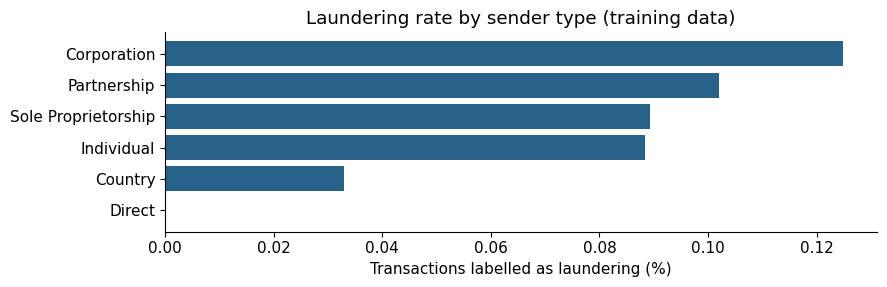

In [17]:
sender_types = accounts.select(
    F.col("bank_id").alias("from_bank"), F.col("account_number").alias("sender_account"),
    F.trim(F.regexp_replace("entity_name", r"\s*#.*$", "")).alias("entity_type"),
)
sender_training = train_df.join(sender_types, ["from_bank", "sender_account"], "left")
entity_rows = sender_training.groupBy("entity_type").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy(F.desc("rate")).collect()
assert all(r.entity_type for r in entity_rows)
plot_rates(entity_rows, "entity_type", "Laundering rate by sender type", "sender_entities.png")

Corporation has the highest observed rate, with 922 positives among 738,357 transactions. Partnership has the largest positive count, at 953. Rate and count answer different questions. Individual has only two positive records, so its rate has limited support.

#### Payment formats
Reuse Assessment 1’s payment format and currency grouping. The first table shows the ten combinations with the most training transactions. Amounts are totalled only within a currency. The chart compares label rates across formats.

Format,Currency,Transactions,Amount paid,Label 1
Cheque,US Dollar,"371,601","135,593,260,872.33",68
Credit Card,US Dollar,"265,802","867,469,988.60",46
Cheque,Euro,"231,310","78,733,035,755.15",56
Credit Card,Euro,"165,811","458,251,975.77",32
ACH,US Dollar,"125,951","119,582,101,279.41",841
Cash,US Dollar,"98,389","49,491,740,088.80",22
Reinvestment,US Dollar,"97,720","24,126,996,655.29",0
Bitcoin,Bitcoin,"76,898","1,494,323.14",31
ACH,Euro,"73,827","55,518,485,469.87",631
Reinvestment,Euro,"61,039","13,772,379,387.88",0


Payment format,Transactions,Label 1,Rate (%)
ACH,"315,374","2,340",0.7420
Bitcoin,"76,937",31,0.0403
Cash,"257,554",60,0.0233
Cheque,"977,805",192,0.0196
Credit Card,"694,028",110,0.0158
Wire,"90,238",0,0.0000
Reinvestment,"252,099",0,0.0000


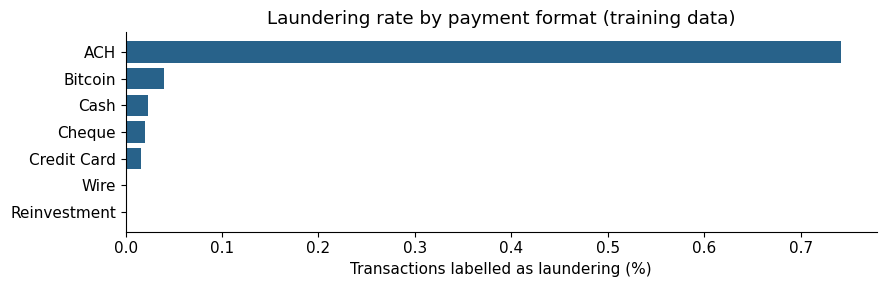

In [18]:
payment_summary = train_df.groupBy("payment_format", "payment_currency").agg(
    F.count("*").alias("transactions"), F.sum("amount_paid").alias("amount_paid"),
    F.sum("is_laundering").alias("positives"),
)
show_table(["Format", "Currency", "Transactions", "Amount paid", "Label 1"], [
    (r.payment_format, r.payment_currency, f"{r.transactions:,}", f"{r.amount_paid:,.2f}", r.positives)
    for r in payment_summary.orderBy(F.desc("transactions")).limit(10).collect()
])
format_rows = train_df.groupBy("payment_format").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy(F.desc("rate")).collect()
plot_rates(format_rows, "payment_format", "Laundering rate by payment format", "payment_formats.png")

ACH contains 2,340 of the 2,733 training positives. Its rate is much higher than the other formats, making payment format a useful candidate feature. Zero observed positives for a format do not establish that future payments are safe.

#### Payment currencies
Compare both the number and proportion of laundering labels. Currency names identify units of payment and are not reliable evidence of where a transaction took place.

Payment currency,Transactions,Label 1,Rate (%)
Saudi Riyal,"46,940",191,0.4069
Euro,"612,713",732,0.1195
Yen,"81,330",86,0.1057
Australian Dollar,"71,778",71,0.0989
US Dollar,"993,890",977,0.0983
Swiss Franc,"123,155",111,0.0901
Canadian Dollar,"73,212",65,0.0888
Yuan,"112,238",99,0.0882
Rupee,"100,047",88,0.0880
Ruble,"81,242",71,0.0874


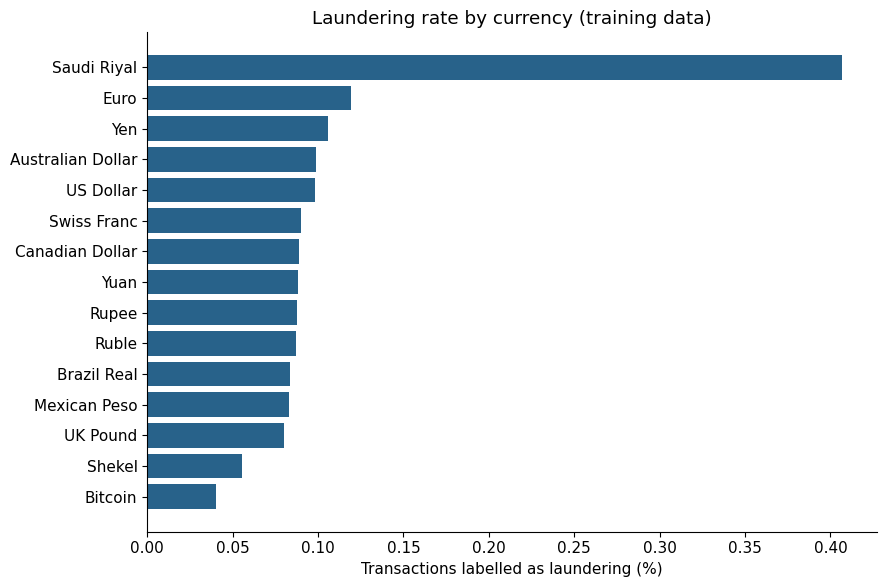

In [19]:
currency_rows = train_df.groupBy("payment_currency").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy(F.desc("rate")).collect()
plot_rates(currency_rows, "payment_currency", "Laundering rate by currency", "payment_currencies.png")

Saudi Riyal has the highest rate at 0.4069%, with 191 positives. USD and Euro have the largest positive counts, at 977 and 732. A high rate is different from a large number of cases; both matter when deciding which patterns deserve attention.

#### Does the payment format pattern change across currencies?
Compare ACH with all other formats within each currency. This gives an overview with two bars per currency; the next heatmap keeps all formats separate. Rates use the transaction count of each currency and format group, rather than the size of the whole dataset.

In [20]:
format_currency = train_df.withColumn(
    "format_group", F.when(F.col("payment_format") == "ACH", "ACH").otherwise("Other formats")
).groupBy("payment_currency", "format_group").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).collect()
currencies = [r.payment_currency for r in currency_rows]
rates = {(r.payment_currency, r.format_group): r.rate for r in format_currency}
show_table(["Currency", "Format group", "Transactions", "Label 1", "Rate (%)"], [
    (r.payment_currency, r.format_group, f"{r.transactions:,}", r.positives, f"{r.rate:.3f}")
    for r in sorted(format_currency, key=lambda r: r.rate, reverse=True)[:6]
])

Currency,Format group,Transactions,Label 1,Rate (%)
Saudi Riyal,ACH,"5,191",186,3.583
Euro,ACH,"73,827",631,0.855
Yen,ACH,"9,590",78,0.813
Australian Dollar,ACH,"7,825",62,0.792
Swiss Franc,ACH,"13,647",95,0.696
Mexican Peso,ACH,"6,418",44,0.686


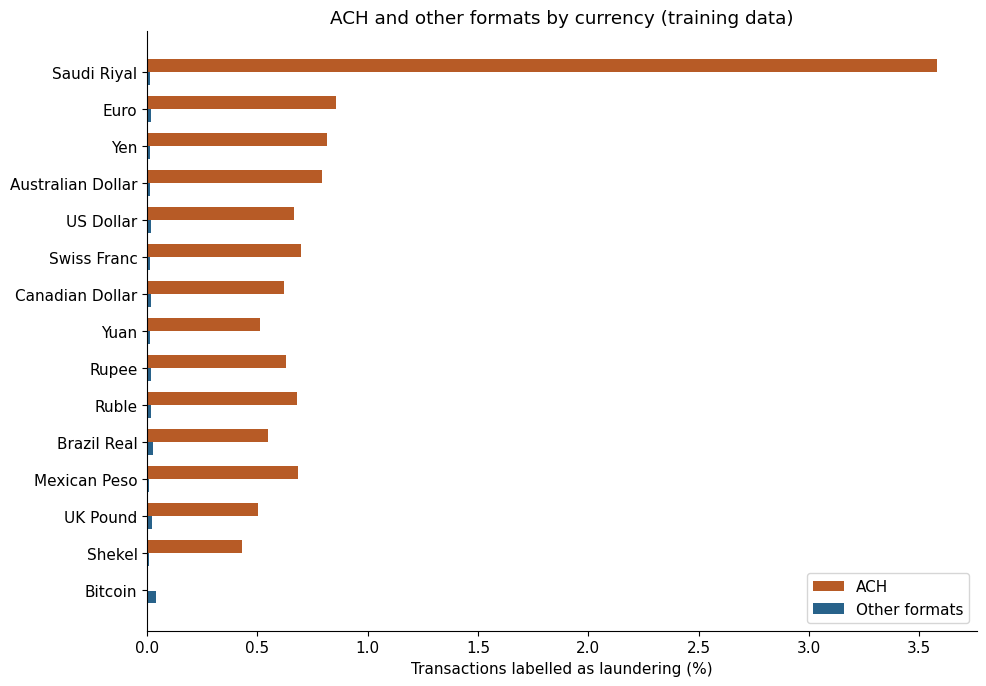

In [21]:
positions = np.arange(len(currencies))
plt.figure(figsize=(10, 7))
plt.barh(positions - 0.18, [rates.get((c, "ACH"), np.nan) for c in currencies],
         height=0.35, label="ACH", color=ORANGE)
plt.barh(positions + 0.18, [rates.get((c, "Other formats"), np.nan) for c in currencies],
         height=0.35, label="Other formats", color=BLUE)
plt.yticks(positions, currencies)
plt.gca().invert_yaxis()
plt.xlabel("Transactions labelled as laundering (%)")
plt.title("ACH and other formats by currency (training data)")
plt.legend()
save_plot("format_currency_comparison.png")

Saudi Riyal ACH payments have a 3.58% rate, compared with 0.67% for USD ACH and 0.85% for Euro ACH. ACH accounts for 186 of the 191 Saudi Riyal positives. This shows why format and currency should be considered together. The Bitcoin-currency ACH group has only 18 transactions and no positives, so that comparison is particularly limited. These results do not support copying Assessment 1’s Saudi Riyal threshold into the model.

#### Payment format and currency heatmap
The heatmap keeps each payment format separate instead of combining the non-ACH formats. Colour shows the percentage of transactions labelled as laundering within each format and currency. Grey cells contain fewer than 1,000 transactions or no records; their rates are not displayed. This is a readability rule, not a significance test. The count table shows the support behind every cell.

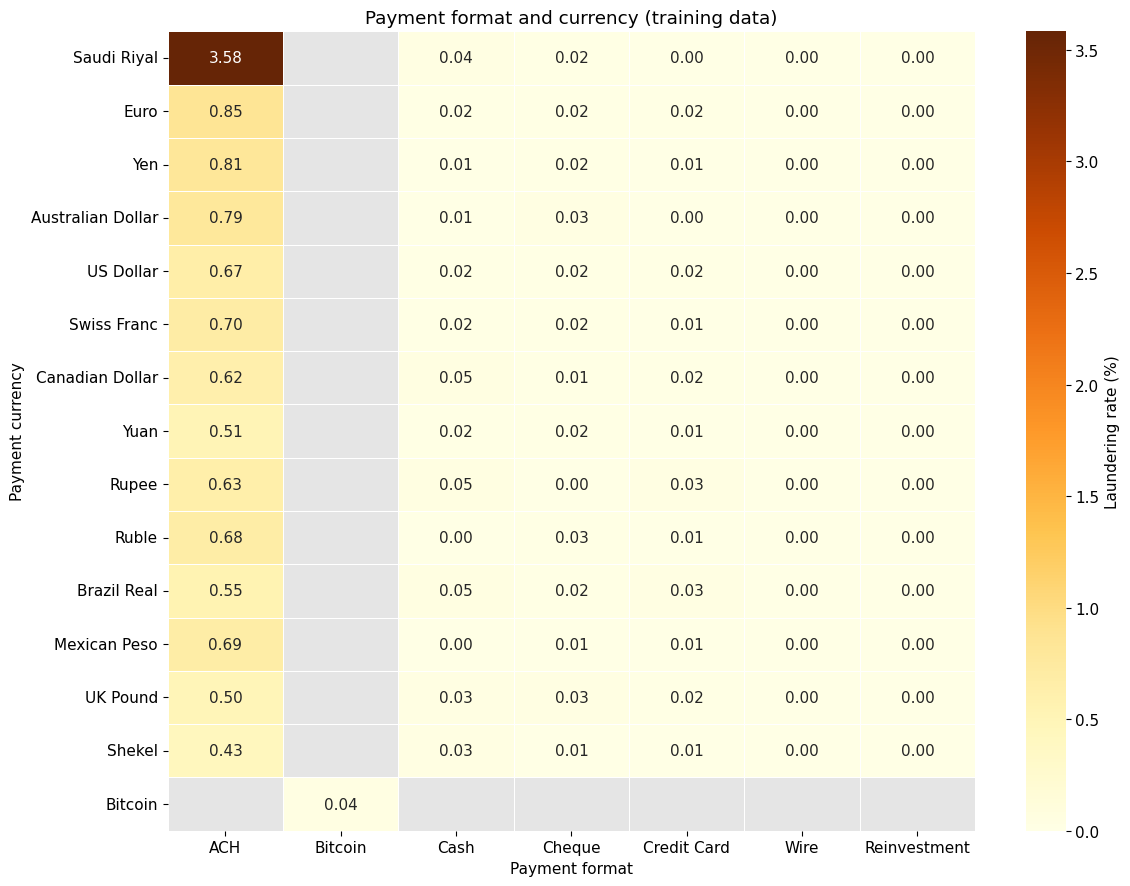

payment_format,ACH,Bitcoin,Cash,Cheque,Credit Card,Wire,Reinvestment
payment_currency,,,,,,,
Saudi Riyal,5191,0,4972,18130,12573,1853,4221
Euro,73827,18,59696,231310,165811,21012,61039
Yen,9590,0,8362,31066,21592,2900,7820
Australian Dollar,7825,0,7189,27842,19682,2542,6698
US Dollar,125951,10,98389,371601,265802,34417,97720
Swiss Franc,13647,4,12545,47290,33158,4388,12123
Canadian Dollar,8696,0,7344,27907,19784,2515,6966
Yuan,16995,1,10773,40891,29151,3807,10620
Rupee,11728,6,10270,38632,26326,3541,9544


In [22]:
payment_grid = payment_summary.withColumn("rate", 100 * F.col("positives") / F.col("transactions")).toPandas()
format_order = [r.payment_format for r in format_rows]
rate_grid = payment_grid.pivot(index="payment_currency", columns="payment_format", values="rate").reindex(index=currencies, columns=format_order)
count_grid = payment_grid.pivot(index="payment_currency", columns="payment_format", values="transactions").reindex_like(rate_grid).fillna(0)
plt.figure(figsize=(12, 9))
plt.gca().set_facecolor("#E5E5E5")
sns.heatmap(rate_grid, mask=count_grid < 1000, annot=True, fmt=".2f", cmap="YlOrBr",
            vmin=0, linewidths=0.4, cbar_kws={"label": "Laundering rate (%)"})
plt.title("Payment format and currency (training data)")
plt.xlabel("Payment format")
plt.ylabel("Payment currency")
plt.xticks(rotation=0)
save_plot("format_currency_heatmap.png")
display(count_grid.astype(int))

ACH stands out across the displayed fiat currencies, with Saudi Riyal ACH reaching 3.58%. Keeping the other formats separate also shows that their rates are much lower than ACH rather than uniformly high for the currency as a whole. Most Bitcoin-format transactions use Bitcoin currency; the grey cells identify sparse or absent combinations, not zero risk. Rates are rounded to two decimal places, so a displayed 0.00 can also represent a small nonzero rate.

#### Amount box plots across currencies
Compare normal and laundering payments within every currency. Each box covers the middle 50% of amounts, its central line is the median, and its whiskers mark the 5th and 95th percentiles. Values outside the whiskers are not drawn individually. The plots use log10(1 + amount paid) so both small and large payments remain visible.

All training records contribute to Spark’s approximate percentiles. Each panel has its own vertical scale and currency units, so compare the two classes within a panel, not monetary values between currencies. The counts in each title show the support for the comparison.

In [23]:
amount_quantiles = train_df.groupBy("payment_currency", "is_laundering").agg(
    F.count("*").alias("transactions"),
    F.percentile_approx("amount_paid", [0.05, 0.25, 0.5, 0.75, 0.95], 10000).alias("quantiles"),
).toPandas()
assert amount_quantiles.transactions.sum() == training_count
assert amount_quantiles.loc[amount_quantiles.is_laundering == 1, "transactions"].sum() == training_positives
amount_quantiles["median"] = amount_quantiles.quantiles.map(lambda q: q[2])

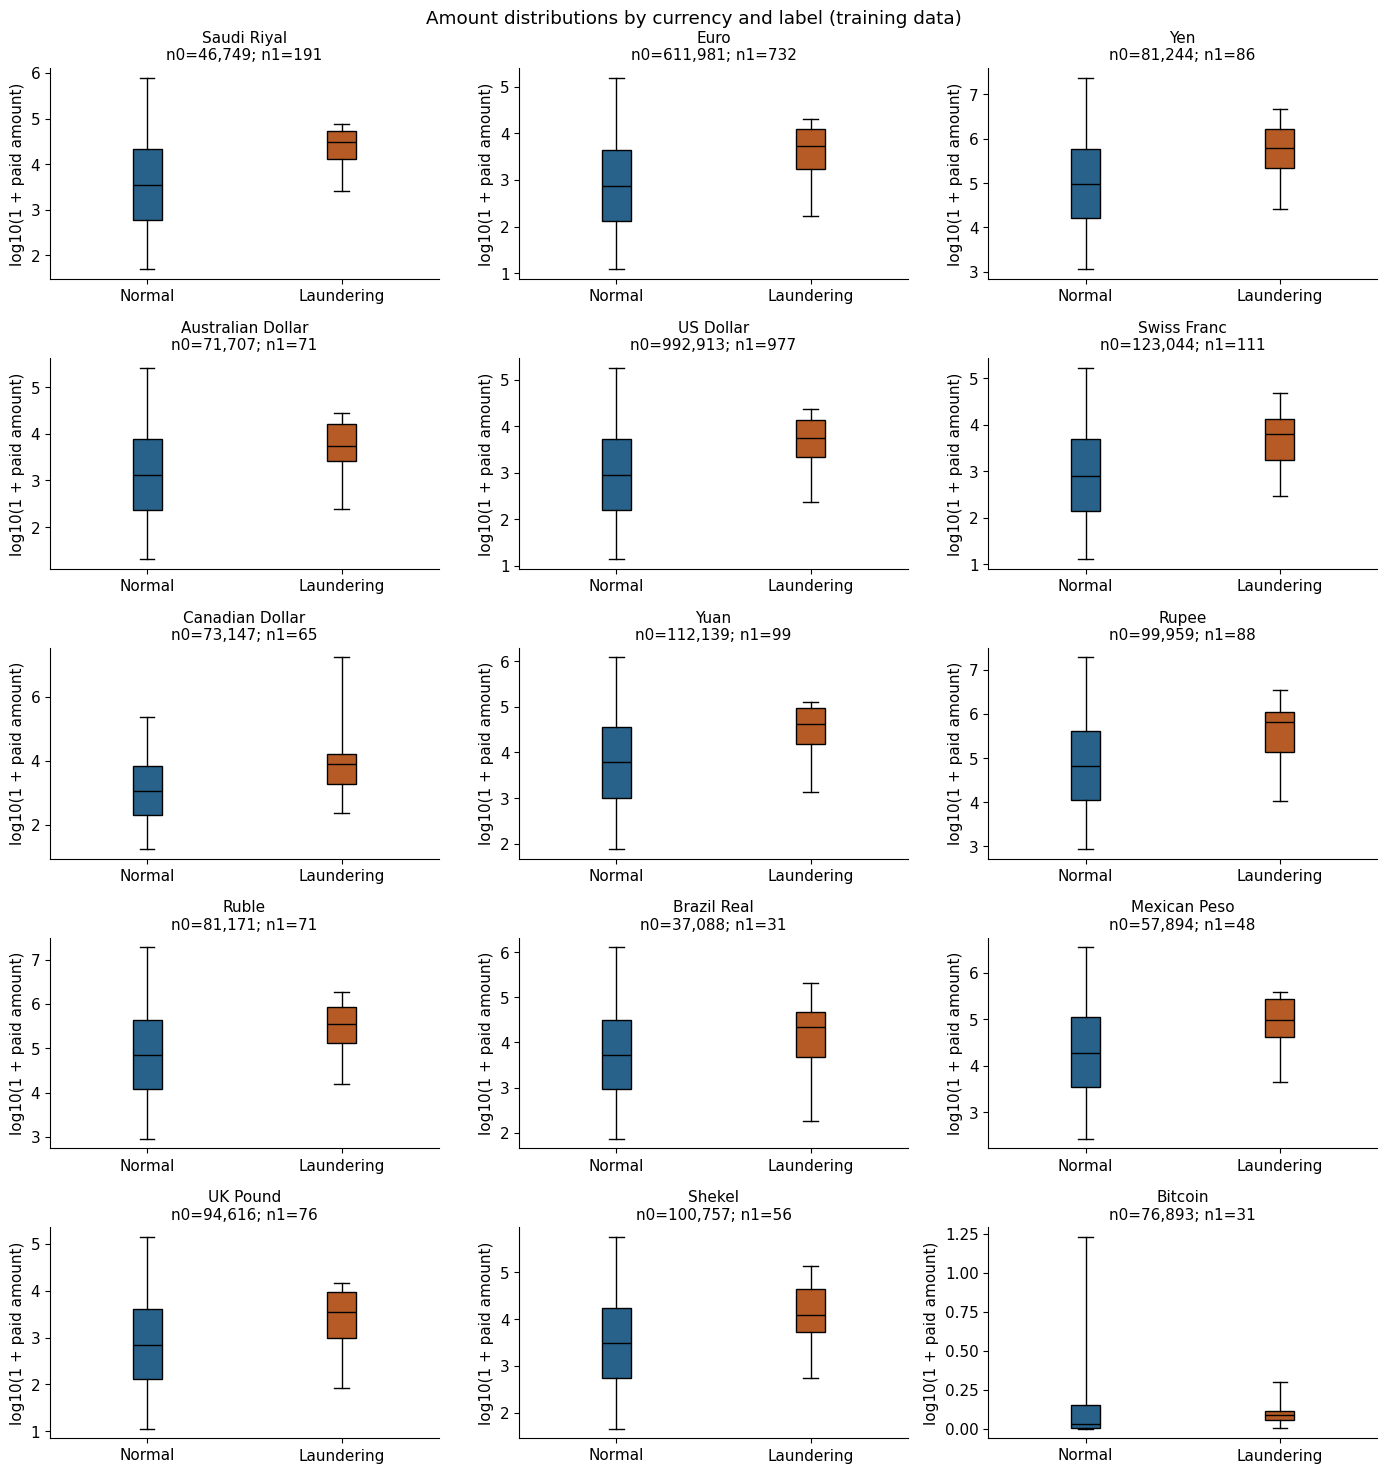

In [24]:
fig, axes = plt.subplots(5, 3, figsize=(14, 15))
for ax, currency in zip(axes.flat, currencies):
    rows = amount_quantiles[amount_quantiles.payment_currency == currency].sort_values("is_laundering")
    boxes = []
    for q in rows.quantiles:
        low, q1, median, q3, high = np.log10(1 + np.array(q))
        boxes.append(dict(whislo=low, q1=q1, med=median, q3=q3, whishi=high))
    artists = ax.bxp(boxes, showfliers=False, patch_artist=True, medianprops={"color": "black"})
    for box, colour in zip(artists["boxes"], [BLUE, ORANGE]):
        box.set_facecolor(colour)
    counts = rows.transactions.tolist()
    ax.set_title(f"{currency}\nn0={counts[0]:,}; n1={counts[1]:,}", fontsize=11)
    ax.set_xticks([1, 2], ["Normal", "Laundering"])
    ax.set_ylabel("log10(1 + paid amount)")
fig.suptitle("Amount distributions by currency and label (training data)")
save_plot("amount_boxplots_all_currencies.png")

The laundering median is higher than the normal median in all 15 currencies. For example, the approximate medians are USD 5,517.96 versus 899.49, Euro 5,313.33 versus 742.79, and Saudi Riyal 30,855.39 versus 3,455.32. These are comparisons within each currency; the numbers should not be compared as equivalent monetary values across currencies.

The boxes and whiskers still overlap, and the positive groups contain only 31 to 977 observations. Higher typical amounts therefore provide context rather than a clean boundary between labels. Different payment-format mixes can also contribute to these pooled differences.

#### Amount histograms for three contrasting currencies
Box plots summarise spread; histograms show the shape of each distribution. USD and Euro have the most positive records, while Saudi Riyal has the highest overall label rate. These three panels provide a closer view of those groups, alongside the all-currency box plots above.

Each class is normalised separately to 100%, so its shape remains visible despite the class imbalance. The plots use every training record in the selected currencies and bins of width 0.25 on log10(1 + amount paid). They do not show the relative sizes of the two classes.

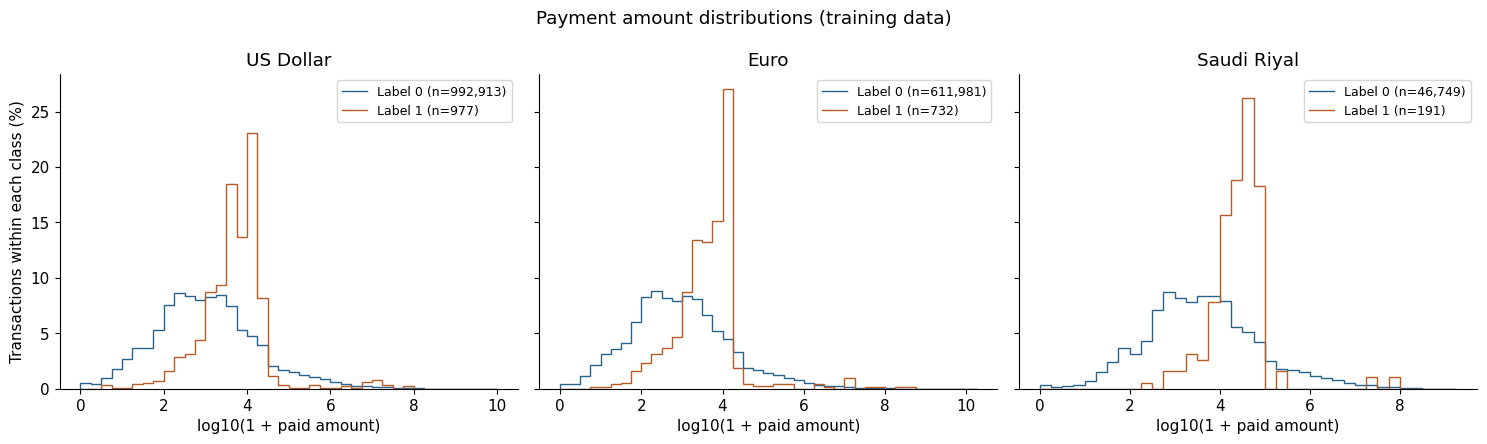

In [25]:
focus_currencies = ["US Dollar", "Euro", "Saudi Riyal"]
amount_bins = train_df.filter(F.col("payment_currency").isin(focus_currencies)).groupBy(
    "payment_currency", "is_laundering",
    F.floor(F.log10(F.col("amount_paid") + 1) * 4).cast("int").alias("bin"),
).count().toPandas()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, currency in zip(axes, focus_currencies):
    rows = amount_bins[amount_bins.payment_currency == currency]
    counts = rows.pivot(index="bin", columns="is_laundering", values="count").fillna(0)
    counts = counts.reindex(range(int(counts.index.max()) + 1), fill_value=0)
    percentages = counts / counts.sum() * 100
    for label, colour in [(0, BLUE), (1, ORANGE)]:
        ax.stairs(percentages[label], np.arange(len(counts) + 1) / 4,
                  label=f"Label {label} (n={int(counts[label].sum()):,})", color=colour)
    ax.set_title(currency)
    ax.set_xlabel("log10(1 + paid amount)")
    ax.legend(fontsize=9)
axes[0].set_ylabel("Transactions within each class (%)")
fig.suptitle("Payment amount distributions (training data)")
save_plot("amount_histograms_three_currencies.png")

The positive distributions are more concentrated than the normal distributions in these three currencies. Their tallest bins are around 10,000 to 17,800 for USD and Euro, and 31,600 to 56,200 for Saudi Riyal. Those bins contain approximately 23%, 27% and 26% of the respective positive classes.

Normal payments also occur throughout those ranges and extend into large upper tails. The histograms explain why a shift in the median does not make amount alone a reliable classifier. The curves show within-class percentages, not the probability that an amount is laundering.

#### Relative amount and laundering across all currencies
Is a relatively large payment more likely to carry a laundering label? Calculate the median, 90th and 99th percentiles separately for each payment currency, then put each transaction into one of four amount bands. A yen payment is compared with other yen payments, and a Saudi Riyal payment with other Saudi Riyal payments. No exchange-rate conversion or addition of different currency amounts is needed.

All 15 currencies contribute. Percentiles are approximate, and tied amounts mean the groups need not contain exactly 50%, 40%, 9% and 1% of records. The combined rates still reflect the mix of currencies and formats, so they are descriptive rather than an isolated effect of amount. The cutoffs are calculated from training data only and are used here for exploration.

Amount band,Transactions,Label 1,Rate (%)
1. Up to median,"1,331,885",384,0.0288
2. Median to 90th percentile,"1,065,597","2,237",0.2099
3. 90th to 99th percentile,"239,751",58,0.0242
4. Above 99th percentile,"26,802",54,0.2015


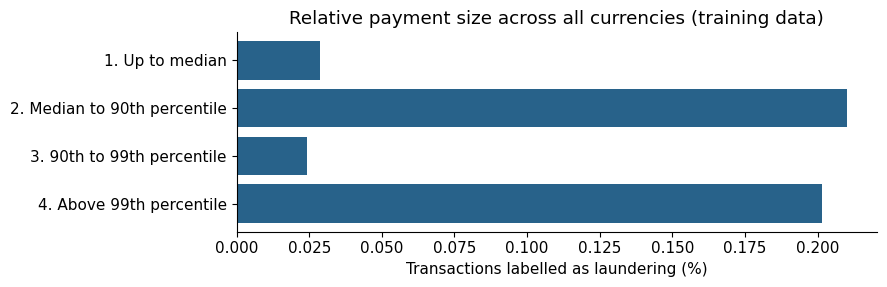

In [26]:
amount_cutoffs = train_df.groupBy("payment_currency").agg(
    F.percentile_approx("amount_paid", [0.5, 0.9, 0.99], 10000).alias("cutoffs")
)
amount_bands = train_df.join(amount_cutoffs, "payment_currency").withColumn(
    "amount_band",
    F.when(F.col("amount_paid") <= F.col("cutoffs")[0], "1. Up to median")
     .when(F.col("amount_paid") <= F.col("cutoffs")[1], "2. Median to 90th percentile")
     .when(F.col("amount_paid") <= F.col("cutoffs")[2], "3. 90th to 99th percentile")
     .otherwise("4. Above 99th percentile"),
)
amount_rows = amount_bands.groupBy("amount_band").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy("amount_band").collect()
plot_rates(amount_rows, "amount_band", "Relative payment size across all currencies", "relative_amounts.png")

The median-to-90th-percentile band has the highest observed rate, 0.2099%, and contains 2,237 of the 2,733 positives, or 81.85%. Payments above the 99th percentile have a similar rate of 0.2015%, but only 54 positives. The intervening 90th-to-99th-percentile band has a much lower rate of 0.0242%.

The relationship is not a steady increase in laundering rate as relative amount grows. A single large-payment threshold would miss much of the observed pattern. Relative size is useful context alongside payment format and currency, but these pooled rates do not prove an independent effect of amount.

#### Paid and received amount check
Do the two amount columns provide different information? Compare them across all training records where both amounts use the same currency. Differences between amounts in different currencies would mix units.

In [27]:
same_currency = train_df.filter(F.col("payment_currency") == F.col("receiving_currency"))
paired_amount_summary = same_currency.groupBy("payment_currency").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    F.sum(F.when(F.col("amount_paid") != F.col("amount_received"), 1).otherwise(0)).alias("unequal_amounts"),
).toPandas()
display(paired_amount_summary.sort_values("transactions", ascending=False))

,payment_currency,transactions,positives,unequal_amounts
0,US Dollar,973630,977,0
3,Euro,605100,732,0
12,Swiss Franc,122933,111,0
4,Yuan,106850,99,0
13,Shekel,100759,56,0
10,Rupee,99419,88,0
1,UK Pound,93219,76,0
14,Ruble,81076,71,0
5,Yen,80497,86,0
7,Bitcoin,76898,31,0


Paid and received amounts are identical in all 2,626,282 same-currency training transactions, across all 15 currencies. A scatter plot of this pair would collapse onto one line and add little information.

For these records, amount received duplicates amount paid. Cross-currency amounts were excluded because their difference would mix units. This supports avoiding a raw paid-minus-received feature across the whole dataset.

#### Does payment format change the amount relationship?
The pooled amount comparison shows a peak between the median and 90th percentile. Is that pattern present in every payment format, or concentrated in a particular group?

Use the same currency-specific amount bands as above, then calculate the labelled rate within each payment format and band. The heatmap includes every training transaction across all 15 currencies. Each cell gives the percentage and the number of positive records over the total number of records. A zero means no observed positives, not zero future risk. The credit card group above the 99th percentile contains just one record.

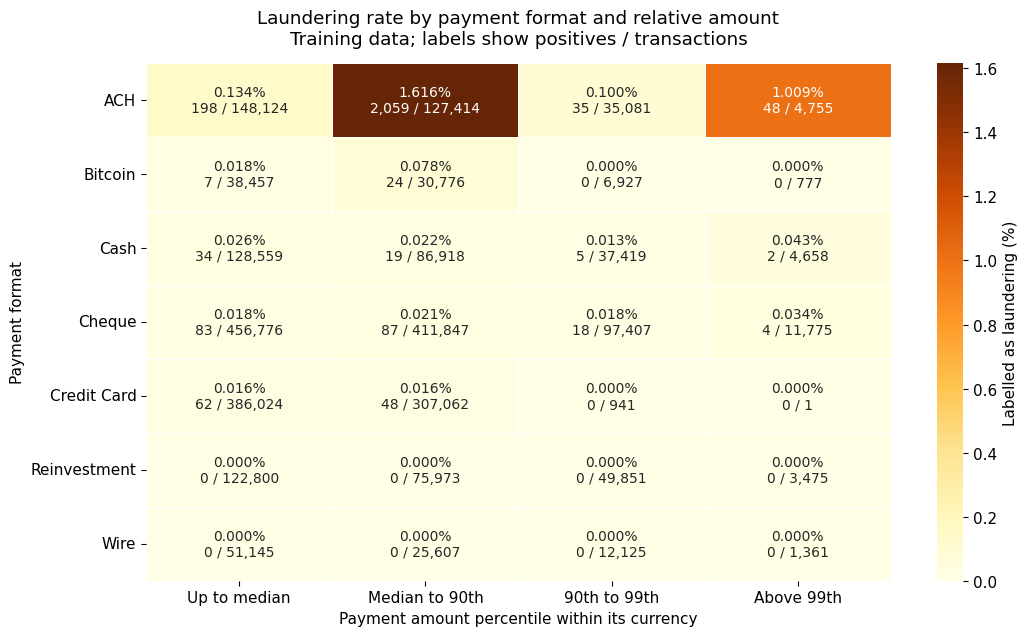

In [28]:
amount_format = amount_bands.groupBy("payment_format", "amount_band").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).toPandas()
assert amount_format.transactions.sum() == training_count
assert amount_format.positives.sum() == training_positives
band_order = sorted(amount_format.amount_band.unique())
format_order = ["ACH", "Bitcoin", "Cash", "Cheque", "Credit Card", "Reinvestment", "Wire"]
amount_format["label"] = amount_format.apply(
    lambda r: f"{r.rate:.3f}%\n{r.positives:,} / {r.transactions:,}", axis=1,
)
rate_grid = amount_format.pivot(index="payment_format", columns="amount_band", values="rate").reindex(format_order)[band_order]
label_grid = amount_format.pivot(index="payment_format", columns="amount_band", values="label").reindex(format_order)[band_order]
plt.figure(figsize=(11, 6.5))
sns.heatmap(rate_grid, annot=label_grid, fmt="", cmap="YlOrBr", vmin=0,
            linewidths=0.5, annot_kws={"fontsize": 10}, cbar_kws={"label": "Labelled as laundering (%)"})
plt.xticks(np.arange(4) + 0.5, ["Up to median", "Median to 90th", "90th to 99th", "Above 99th"], rotation=0)
plt.yticks(rotation=0)
plt.xlabel("Payment amount percentile within its currency")
plt.ylabel("Payment format")
plt.title("Laundering rate by payment format and relative amount\nTraining data; labels show positives / transactions", pad=14)
save_plot("amount_format_relationship.png")

The middle amount band is mainly an ACH pattern. ACH payments between the median and 90th percentile contain 2,059 positives among 127,414 transactions, a rate of 1.616%. This group accounts for only 4.78% of training transactions but 75.34% of all positive labels. It also supplies 92.04% of the positives in the pooled middle band.

Within ACH, this rate is about 12.1 times the rate below the median (0.134%). It drops to 0.100% in the 90th-to-99th band before rising to 1.009% above the 99th percentile. Cash, cheque and credit card payments do not show the same middle-band peak. Transaction size therefore needs to be considered together with payment format; a rule that only looks for the largest payments would miss most of the labelled cases.

These are descriptive training results. Even in the ACH middle band, 98.384% of transactions have label 0. The concentration suggests a useful feature relationship, not a sufficient detection rule or an independently measured causal effect.

#### Does the ACH pattern hold across currencies?
Compare the same format and relative amount band across all currencies: ACH payments between each currency's median and 90th percentile. Amounts are still compared with other payments in the same currency, without converting or adding unlike units.

The chart shows the labelled percentage, with positive and total counts alongside each bar. This helps distinguish a high rate from a large number of cases. The percentiles use all training payments in each currency, not only ACH payments.

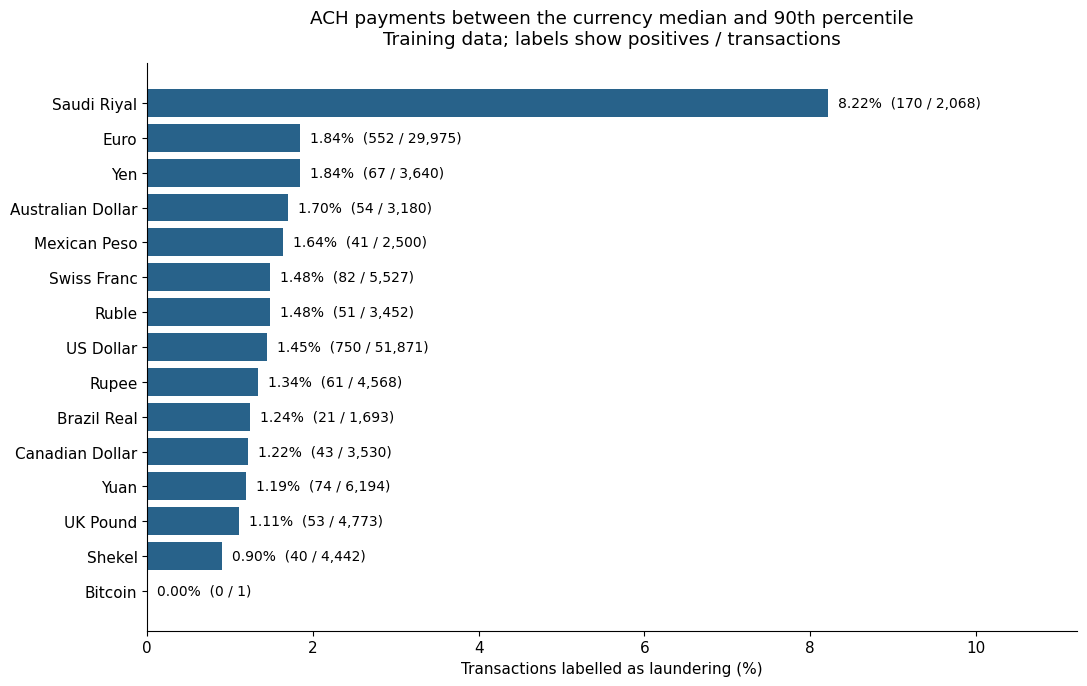

In [29]:
ach_middle = amount_bands.filter(
    (F.col("payment_format") == "ACH") & (F.col("amount_band") == band_order[1])
).groupBy("payment_currency").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).toPandas().sort_values("rate", ascending=False)
plt.figure(figsize=(11, 7))
plt.barh(ach_middle.payment_currency, ach_middle.rate, color=BLUE)
plt.gca().invert_yaxis()
for i, row in enumerate(ach_middle.itertuples()):
    plt.text(row.rate + 0.12, i, f"{row.rate:.2f}%  ({row.positives:,} / {row.transactions:,})", va="center", fontsize=10)
plt.xlim(0, ach_middle.rate.max() + 3)
plt.xlabel("Transactions labelled as laundering (%)")
plt.title("ACH payments between the currency median and 90th percentile\nTraining data; labels show positives / transactions", pad=14)
save_plot("ach_middle_by_currency.png")

Saudi Riyal stands out even within the same payment format and relative amount band: 170 of 2,068 transactions are positive, or 8.22%. Euro has 552 of 29,975 (1.84%) and USD has 750 of 51,871 (1.45%). Saudi Riyal has the highest observed rate, while USD contributes the largest number of cases in this group.

This narrows the earlier Saudi Riyal finding to a specific combination of currency, format and relative size. It is not explained solely by comparing ACH in one currency with other formats in another. However, the bands cover different monetary ranges and may still differ in entities, banks and timing. The single Bitcoin-denominated ACH record in this band provides too little evidence for a rate comparison.

The modelling implication is to evaluate amount, currency and payment format together. These rates and labels are not predictor columns, and any apparent benefit must be checked on validation data before drawing conclusions about model performance.

#### Transaction timing
Use the original transaction timestamp with the notebook’s UTC convention. Hourly and daily summaries cover all training currencies. Daily counts help show whether a high rate is based on very few records.

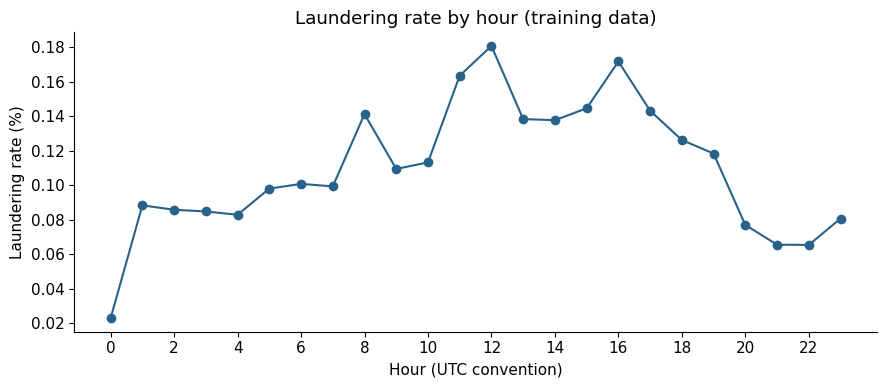

In [30]:
hour_rows = train_df.groupBy(F.hour("timestamp").alias("hour")).agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy("hour").collect()
day_rows = train_df.groupBy(F.date_format("timestamp", "yyyy-MM-dd").alias("date")).agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy("date").collect()
plt.figure(figsize=(9, 4))
plt.plot([r.hour for r in hour_rows], [r.rate for r in hour_rows], marker="o", color=BLUE)
plt.xticks(range(0, 24, 2))
plt.xlabel("Hour (UTC convention)")
plt.ylabel("Laundering rate (%)")
plt.title("Laundering rate by hour (training data)")
save_plot("hourly_rate.png")

Date,Transactions,Label 1,Rate (%)
2022-09-01,"584,378",182,0.031
2022-09-02,"396,284",242,0.061
2022-09-03,"108,861",196,0.180
2022-09-04,"109,264",214,0.196
2022-09-05,"253,487",242,0.095
2022-09-06,"252,434",284,0.113
2022-09-07,"253,643",245,0.097
2022-09-08,"253,058",281,0.111
2022-09-09,"342,588",257,0.075
2022-09-10,"109,437",224,0.205


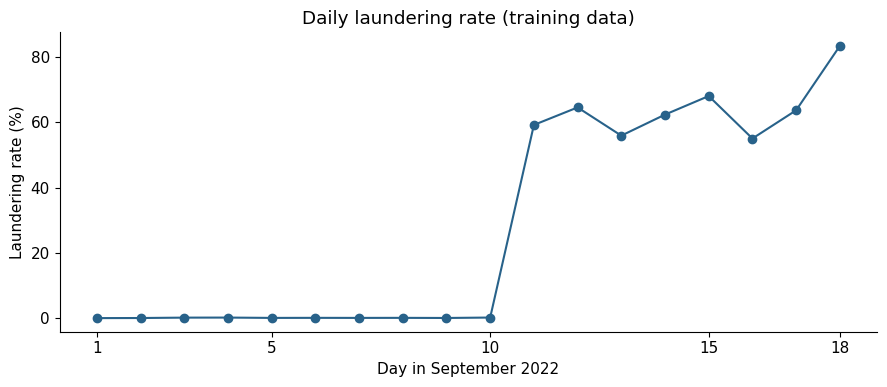

In [31]:
show_table(["Date", "Transactions", "Label 1", "Rate (%)"], [
    (r.date, f"{r.transactions:,}", r.positives, f"{r.rate:.3f}") for r in day_rows
])
plt.figure(figsize=(9, 4))
plt.plot([int(r.date[-2:]) for r in day_rows], [r.rate for r in day_rows], marker="o", color=BLUE)
plt.xticks([1, 5, 10, 15, 18])
plt.xlabel("Day in September 2022")
plt.ylabel("Laundering rate (%)")
plt.title("Daily laundering rate (training data)")
save_plot("daily_rate.png")

After 10 September, only 601 training records remain, including 366 positives. This produces a 60.90% rate, but describes just 0.0226% of the training transactions. The final date has five positives among six records. The daily plot therefore reflects a substantial change in the dataset, not evidence of a recurring seasonal trend.

Absolute calendar date will be excluded from the initial feature set because it could identify this sparse tail. The 333,223 records at midnight also deserve caution. Time features need validation, and our random split does not establish performance on a later period.

#### Weekday and hour together
The heatmap asks whether hourly patterns differ by weekday across all currencies. It focuses on 1 to 10 September, before the sharp drop in daily volume. This is an exploratory view only; no records are removed from the model partitions.

Colour shows the label rate within each weekday and hour. Grey cells would indicate fewer than 1,000 transactions or missing combinations. The period contains only one or two occurrences of each weekday, so it cannot establish a stable weekly cycle. The table gives counts for the five highest displayed rates.

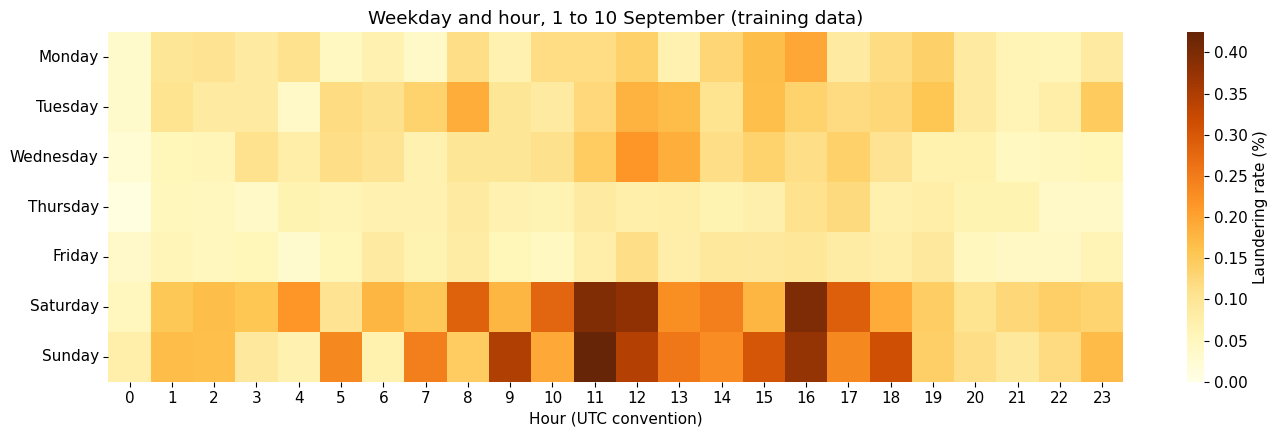

,weekday,hour,transactions,positives,rate
50,Sunday,11,4241,18,0.424428
28,Saturday,16,8515,34,0.399295
39,Saturday,11,8558,34,0.397289
48,Saturday,12,8415,32,0.380273
36,Sunday,16,4255,16,0.376028


In [32]:
time_grid = train_df.filter(F.col("timestamp") < "2022-09-11").groupBy(
    F.date_format("timestamp", "EEEE").alias("weekday"), F.hour("timestamp").alias("hour"),
).agg(F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
      (100 * F.avg("is_laundering")).alias("rate")).toPandas()
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
hourly_rates = time_grid.pivot(index="weekday", columns="hour", values="rate").reindex(index=days, columns=range(24))
hourly_counts = time_grid.pivot(index="weekday", columns="hour", values="transactions").reindex_like(hourly_rates).fillna(0)
plt.figure(figsize=(14, 4.5))
plt.gca().set_facecolor("#E5E5E5")
sns.heatmap(hourly_rates, mask=hourly_counts < 1000, cmap="YlOrBr", vmin=0,
            cbar_kws={"label": "Laundering rate (%)"})
plt.title("Weekday and hour, 1 to 10 September (training data)")
plt.xlabel("Hour (UTC convention)")
plt.ylabel("")
plt.yticks(rotation=0)
save_plot("weekday_hour_heatmap.png")
display(time_grid[time_grid.transactions >= 1000].sort_values("rate", ascending=False).head(5))

Weekend cells are generally darker around late morning and afternoon. For 1 to 10 September, Saturday and Sunday have overall rates of 0.1924% and 0.1959%, compared with weekday rates from 0.0553% to 0.1125%. The highest cell is Sunday at 11:00, with 18 positives among 4,241 transactions, or 0.4244%.

This supports examining weekday and hour together. It does not establish a stable weekend effect: the window contains just two Saturdays and one Sunday, and format or currency mix may also contribute. Validation should determine whether these time features help the model.

#### Bank and currency relationships
Do payments within the same bank have a different label rate from payments between banks? Does changing currency show a different pattern? Both comparisons include all training currencies. Bank and currency differences do not by themselves identify an international payment.

Bank relationship,Transactions,Label 1,Rate (%)
Different banks,"2,301,360","2,675",0.1162
Same bank,"362,675",58,0.0160


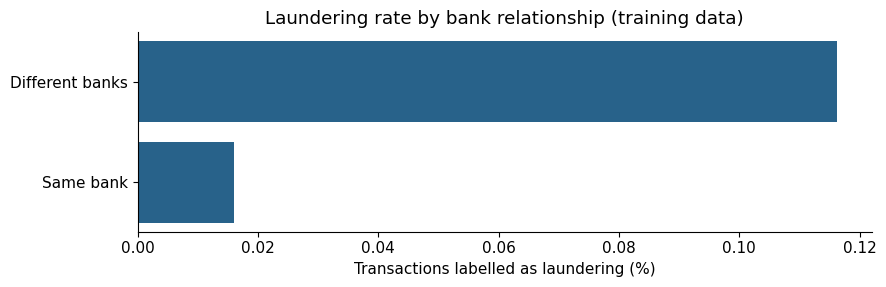

In [33]:
relationship_df = train_df.withColumn(
    "bank_relationship", F.when(F.col("from_bank") == F.col("to_bank"), "Same bank").otherwise("Different banks")
).withColumn(
    "currency_relationship", F.when(F.col("payment_currency") == F.col("receiving_currency"),
                                     "Same currency").otherwise("Different currencies")
)
bank_rows = relationship_df.groupBy("bank_relationship").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy(F.desc("rate")).collect()
plot_rates(bank_rows, "bank_relationship", "Laundering rate by bank relationship", "bank_relationship.png")

Different-bank payments have a 0.1162% label rate, compared with 0.0160% for same-bank payments, about 7.3 times as high. They also contain 2,675 of the 2,733 positives. This supports testing a same-bank indicator, while recognising that other transaction characteristics may explain some of the difference.

Currency relationship,Transactions,Label 1,Rate (%)
Same currency,"2,626,282","2,733",0.1041
Different currencies,"37,753",0,0.0000


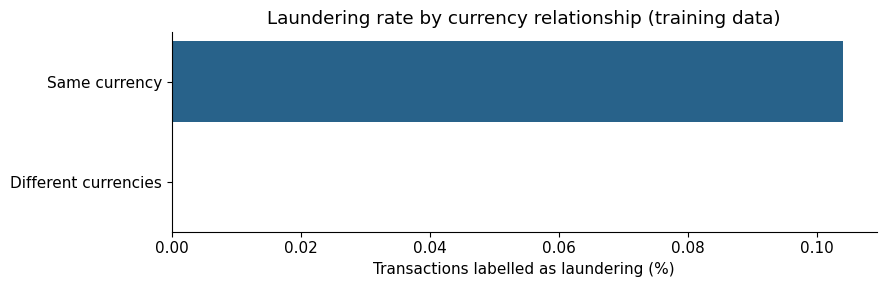

Bank relationship,Currency relationship,Transactions,Label 1
Different banks,Same currency,"2,301,360",2675
Same bank,Different currencies,"37,753",0
Same bank,Same currency,"324,922",58


In [34]:
currency_relationship_rows = relationship_df.groupBy("currency_relationship").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives"),
    (100 * F.avg("is_laundering")).alias("rate"),
).orderBy(F.desc("rate")).collect()
plot_rates(currency_relationship_rows, "currency_relationship", "Laundering rate by currency relationship", "currency_relationship.png")
relationship_joint = relationship_df.groupBy("bank_relationship", "currency_relationship").agg(
    F.count("*").alias("transactions"), F.sum("is_laundering").alias("positives")
).orderBy("bank_relationship", "currency_relationship").collect()
show_table(["Bank relationship", "Currency relationship", "Transactions", "Label 1"], [
    (r.bank_relationship, r.currency_relationship, f"{r.transactions:,}", r.positives)
    for r in relationship_joint
])

All 37,753 currency-changing payments have label 0 and occur within the same bank. This could reflect the synthetic data generation process and should not become an automatic safe-payment rule. The joint table also shows that bank and currency relationships are not independent in this dataset.

#### What carries forward to feature design
The analysis covers all currencies and examines payment format, relative amount, time, bank relationship and currency changes. Format and currency need to be considered together, and the amount comparison provides a way to explore transaction size without treating different currency units as equal.

Candidate inputs must be available when a transaction arrives. The label, exploratory label rates, source IDs, partition assignments and retrospective transfer flags are excluded from predictors. Entity type needs the same static account lookup at training and prediction time. A4 will define the final features and transformations, with preprocessing fitted on training data and model choices assessed on validation data. Test and streaming records remain held out.

The distribution plots show higher typical amounts for the positive class but substantial overlap. The equality check identifies duplicate amount information for same-currency transactions. The amount/format heatmap shows that the pooled middle-band concentration is largely an ACH pattern. The currency comparison identifies a particularly high rate for Saudi Riyal within that group. The weekday/hour heatmap adds a candidate time interaction, with a short-window limitation. These plots guide feature choices without supplying label-derived summaries to the model.

In [35]:
eda_summaries = {
    "entity": entity_rows, "format": format_rows, "currency": currency_rows,
    "format_currency": format_currency, "relative_amount": amount_rows,
    "hour": hour_rows, "date": day_rows, "bank": bank_rows,
    "currency_relationship": currency_relationship_rows, "relationship_joint": relationship_joint,
}
for rows in eda_summaries.values():
    assert sum(r.transactions for r in rows) == training_count
    assert sum(r.positives for r in rows) == training_positives
eda_evidence = {"scope": "training only", "training_rows": training_count,
                "training_positives": training_positives, "baseline_accuracy": baseline_accuracy,
                "summaries": {name: [r.asDict() for r in rows] for name, rows in eda_summaries.items()}}
eda_evidence["additional_plots"] = {
    "amount_quantiles": amount_quantiles.assign(quantiles=amount_quantiles.quantiles.map(list)).to_dict("records"),
    "amount_bins": amount_bins.to_dict("records"),
    "paid_received": paired_amount_summary.to_dict("records"),
    "time_grid": time_grid.to_dict("records"),
    "amount_format": amount_format.drop(columns="label").to_dict("records"),
    "ach_middle": ach_middle.to_dict("records"),
}
(PROJECT_ROOT / ".runtime/training_analysis.json").write_text(json.dumps(eda_evidence, indent=2) + "\n")
_ = train_df.unpersist()

### A4. Engineer features and build the pipeline

### A5. Train and compare models

### A6. Save and reload the selected pipeline

## Part B: Real time streaming
### B1. Kafka producer and message schema

### B2. Read, parse and predict

### B3. Sliding windows, watermark and outputs

### B4. Run the complete stream

### Reflection

### Stop Spark
Run this cell when finished. Start Spark again before continuing with more processing.

In [36]:
for query in spark.streams.active:
    query.stop()
spark.stop()
print("Spark session stopped.")

Spark session stopped.
